<a href="https://colab.research.google.com/github/AbdlHamd/gomycode/blob/Python/Data_vis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Chargement et Préparation des Données

Nous allons générer un jeu de données réaliste basé sur les caractéristiques réelles de ces pays pour la période 1980-2023 afin de pouvoir exécuter et visualiser les étapes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de la reproductibilité
np.random.seed(42)

dates = pd.date_range(start="1980-01-01", end="2023-12-31", freq="D")
pays = ["Égypte", "Tunisie", "Cameroun", "Sénégal", "Angola"]

data_list = []

# Températures moyennes approximatives et tendances pour chaque pays
temp_base = {
    "Égypte": 22.0,
    "Tunisie": 19.0,
    "Cameroun": 25.0,
    "Sénégal": 28.0,
    "Angola": 22.0
}

for p in pays:
    # Simulation d'une légère hausse de température au fil des ans due au réchauffement climatique
    years_offset = (dates.year - 1980) * 0.03

    # Variation saisonnière
    if p in ["Égypte", "Tunisie"]:
        seasonal = np.sin(2 * np.pi * dates.dayofyear / 365.25) * 10
    else:
        # Pays plus proches de l'équateur (faible variation saisonnière)
        seasonal = np.sin(2 * np.pi * dates.dayofyear / 365.25) * 3

    noise = np.random.normal(0, 1.5, size=len(dates))
    temp_mean = temp_base[p] + years_offset + seasonal + noise
    temp_min = temp_mean - np.random.uniform(4, 8, size=len(dates))
    temp_max = temp_mean + np.random.uniform(4, 8, size=len(dates))

    df_country = pd.DataFrame({
        "Date": dates,
        "Pays": p,
        "Temp_Min": temp_min,
        "Temp_Max": temp_max,
        "Temp_Moyenne": temp_mean
    })
    data_list.append(df_country)

df = pd.concat(data_list, ignore_index=True)
display(df.head())
print("\nInformations sur le jeu de données :")
df.info()

,Date,Pays,Temp_Min,Temp_Max,Temp_Moyenne
0,1980-01-01,Égypte,16.426314,29.152976,22.917087
1,1980-01-02,Égypte,17.213337,26.993861,22.136584
2,1980-01-03,Égypte,15.806042,29.644115,23.487376
3,1980-01-04,Égypte,18.672449,30.982918,24.972099
4,1980-01-05,Égypte,14.827768,28.410671,22.507831



Informations sur le jeu de données :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80355 entries, 0 to 80354
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          80355 non-null  datetime64[ns]
 1   Pays          80355 non-null  object        
 2   Temp_Min      80355 non-null  float64       
 3   Temp_Max      80355 non-null  float64       
 4   Temp_Moyenne  80355 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(1)
memory usage: 3.1+ MB


### 2. Fluctuations moyennes de la température en Tunisie et au Cameroun (1980-2023)

Traçons un graphique linéaire pour observer et comparer l'évolution des températures moyennes annuelles dans ces deux pays.

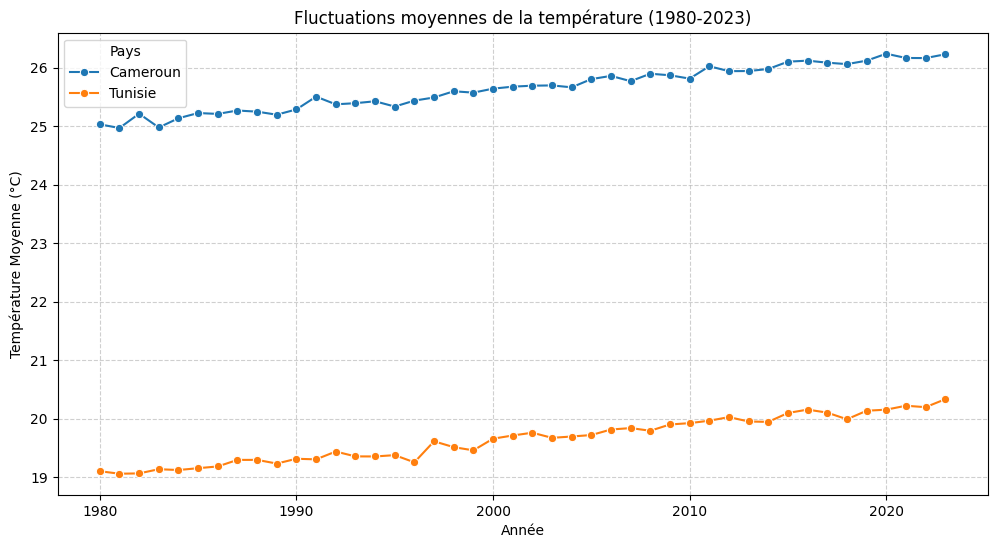

In [2]:
# Agrégation par année pour une meilleure lisibilité des tendances à long terme
df['Annee'] = df['Date'].dt.year
df_tun_cam = df[df['Pays'].isin(['Tunisie', 'Cameroun'])]
df_annuel = df_tun_cam.groupby(['Annee', 'Pays'])['Temp_Moyenne'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_annuel, x='Annee', y='Temp_Moyenne', hue='Pays', marker='o')
plt.title('Fluctuations moyennes de la température (1980-2023)')
plt.xlabel('Année')
plt.ylabel('Température Moyenne (°C)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 3. Zoom sur la période 1980 - 2005 avec personnalisation des axes

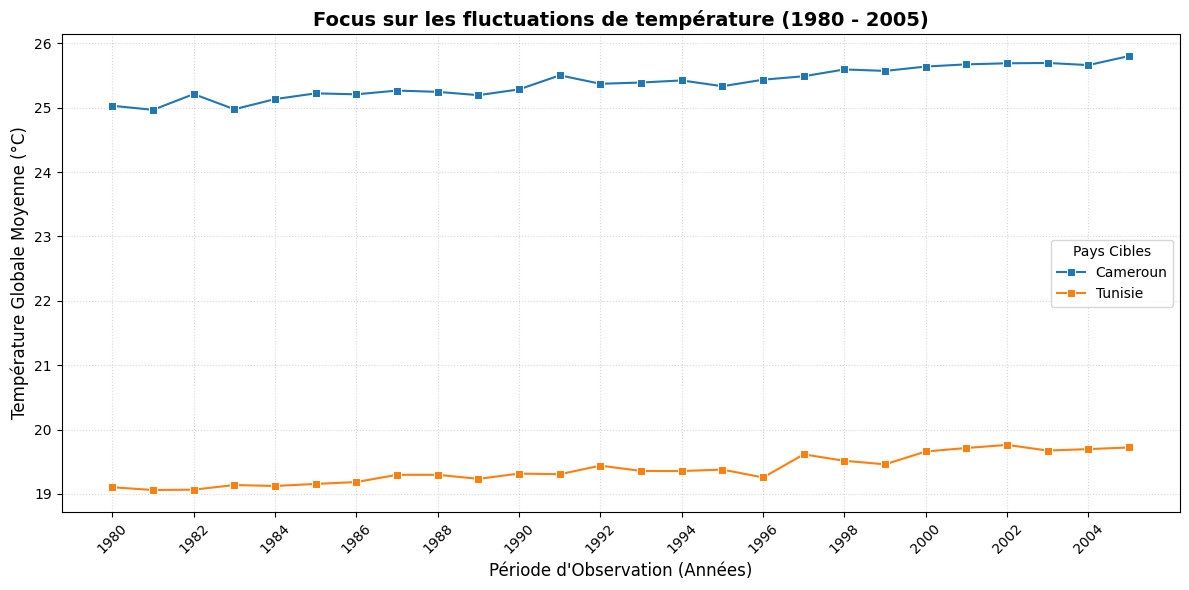

In [3]:
df_annuel_zoom = df_annuel[df_annuel['Annee'] <= 2005]

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_annuel_zoom, x='Annee', y='Temp_Moyenne', hue='Pays', marker='s')
plt.title('Focus sur les fluctuations de température (1980 - 2005)', fontsize=14, fontweight='bold')
plt.xlabel('Période d\'Observation (Années)', fontsize=12)
plt.ylabel('Température Globale Moyenne (°C)', fontsize=12)
plt.xticks(range(1980, 2006, 2), rotation=45)
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.legend(title='Pays Cibles')
plt.tight_layout()
plt.show()

### 4. Histogrammes comparatifs de la distribution de température au Sénégal

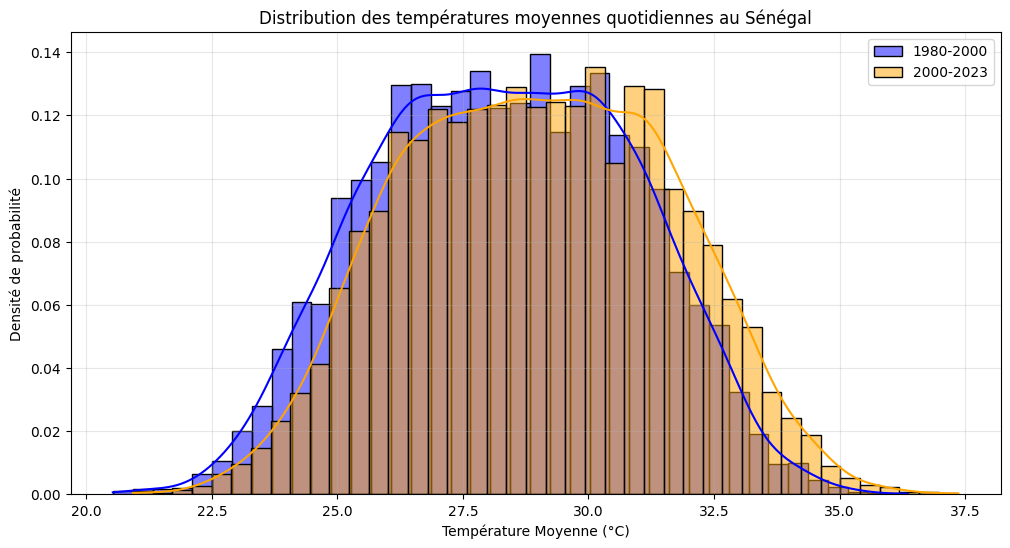

In [4]:
df_senegal = df[df['Pays'] == 'Sénégal'].copy()

# Séparation des deux périodes
periode_1 = df_senegal[(df_senegal['Annee'] >= 1980) & (df_senegal['Annee'] <= 2000)]
periode_2 = df_senegal[(df_senegal['Annee'] > 2000) & (df_senegal['Annee'] <= 2023)]

plt.figure(figsize=(12, 6))
sns.histplot(periode_1['Temp_Moyenne'], color='blue', label='1980-2000', kde=True, stat="density", alpha=0.5)
sns.histplot(periode_2['Temp_Moyenne'], color='orange', label='2000-2023', kde=True, stat="density", alpha=0.5)

plt.title('Distribution des températures moyennes quotidiennes au Sénégal')
plt.xlabel('Température Moyenne (°C)')
plt.ylabel('Densité de probabilité')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 5. Meilleur graphique pour montrer la température moyenne par pays

Le diagramme en barres (Barplot) avec des barres d'erreur (ou un Boxplot) est idéal pour comparer efficacement les moyennes globales de chaque pays.

/tmp/ipykernel_3520/4042881718.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Pays', y='Temp_Moyenne', palette='coolwarm', errorbar='sd')


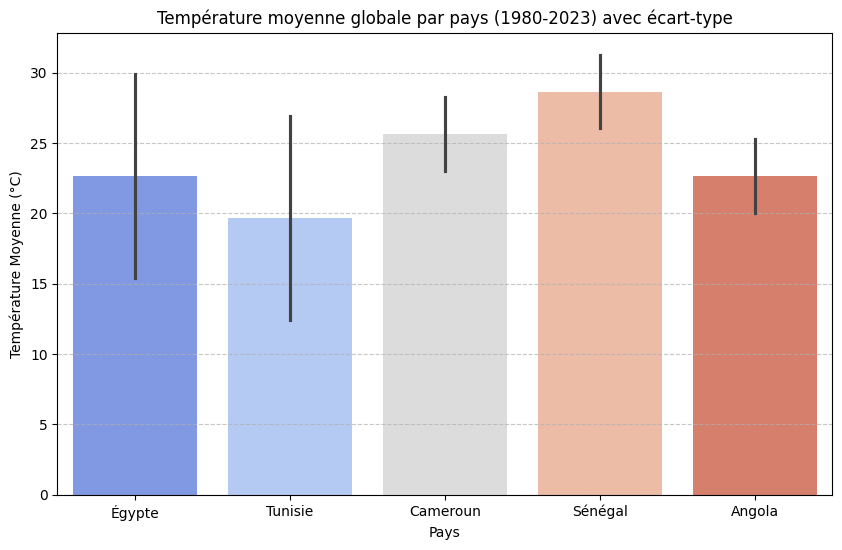

In [5]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Pays', y='Temp_Moyenne', palette='coolwarm', errorbar='sd')
plt.title('Température moyenne globale par pays (1980-2023) avec écart-type')
plt.xlabel('Pays')
plt.ylabel('Température Moyenne (°C)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()